In [88]:
#ruff: noqa: T201, T203
from __future__ import annotations

import os
from pathlib import Path

if Path.cwd().name == 'notebooks':
    os.chdir('..')

In [ ]:
import logging
from concurrent.futures import ThreadPoolExecutor, as_completed
from pprint import pprint
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from tqdm import tqdm

from src.constants import GT_COL_DIVIDER, PRED_COL_DIVIDER, BinaryOutputFormat, LLMCallOutput
from src.LLM_servers.openai import OpenAIServer
from src.onto_access import OntologyAccess
from src.onto_object import OntologyEntryAttr
from src.prompts.system import INITIALIZATION_MESSAGE
from src.utils import calculate_logpropgs_confidence

logging.getLogger().setLevel(logging.WARNING)
load_dotenv()

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
DATA_DIR = Path('/kaggle/input')
if not DATA_DIR.exists():
    DATA_DIR = Path('./data')

OUTPUTS_DIR = Path("./outputs")
METRICS_DIR = Path("./metrics")

## Local matching

In [ ]:
def prompt_with_hierarchy(src_entety: OntologyEntryAttr, tgt_entety: OntologyEntryAttr) -> str:
    return f"""
    Given two entities from different ontologies with their names, parent relationships, and child relationships, determine if these concepts are the same:

    1. Source Entity:
    All Entity names: {src_entety.get_all_entety_names()}
    Parent Entity Namings: {src_entety.get_parents_preferred_names()}
    Child Entity Namings: {src_entety.get_childred_preferred_names()}

    2. Target Entity:
    All Entity names: {tgt_entety.get_all_entety_names()}
    Parent Entity Namings: {tgt_entety.get_parents_preferred_names()}
    Child Entity Namings: {tgt_entety.get_childred_preferred_names()}

    Response with True or False
    """  # noqa: E501


def prompt_only_with_parents(src_entety: OntologyEntryAttr, tgt_entety: OntologyEntryAttr) -> str:
    return f"""
    Given two entities from different ontologies with their names and parent relationships, determine if these concepts are the same:

    1. Source Entity:
    All Entity names: {src_entety.get_all_entety_names()}
    Parent Entity Namings: {src_entety.get_parents_preferred_names()}

    2. Target Entity:
    All Entity names: {tgt_entety.get_all_entety_names()}
    Parent Entity Namings: {tgt_entety.get_parents_preferred_names()}

    Response with True or False
    """  # noqa: E501


def prompt_only_names(src_entety: OntologyEntryAttr, tgt_entety: OntologyEntryAttr) -> str:
    return f"""
    Given two entities from different ontologies with their names, determine if these concepts are the same:

    1. Source Entity:
    All Entity names: {src_entety.get_all_entety_names()}

    2. Target Entity:
    All Entity names: {tgt_entety.get_all_entety_names()}

    Response with True or False
    """


def prompt_only_with_children(src_entety: OntologyEntryAttr, tgt_entety: OntologyEntryAttr) -> str:
    return f"""
    Given two entities from different ontologies with their names and child relationships, determine if these concepts are the same:

    1. Source Entity:
    All Entity names: {src_entety.get_all_entety_names()}
    Child Entity Namings: {src_entety.get_childred_preferred_names()}

    2. Target Entity:
    All Entity names: {tgt_entety.get_all_entety_names()}
    Child Entity Namings: {tgt_entety.get_childred_preferred_names()}

    Response with True or False
    """  # noqa: E501


def prompt_synonyms_subsumption(source_entry: OntologyEntryAttr, target_entry: OntologyEntryAttr) -> str:
    """Create a prompt to determine if one entity's synonyms suggest it subsumes the other."""
    return f"""
    **Task Description:**
    Given two entities with their synonyms, determine if one entity subsumes the other.

    1. **Source Entity Synonyms:** {source_entry.get_synonyms()}
    2. **Target Entity Synonyms:** {target_entry.get_synonyms()}

    Response with True or False
    """


def prompt_one_name_one_synonym(source_entry: OntologyEntryAttr, target_entry: OntologyEntryAttr) -> str:
    """Create a prompt to determine if one entity's synonyms suggest it subsumes the other."""
    return f"""
    **Task Description:**
    Given two entities with their synonyms, determine if one entity subsumes the other.

    1. **Source Entity Synonyms:** {max(list(source_entry.get_synonyms()), key=len)}
    2. **Target Entity Names:** {max(list(target_entry.get_all_entety_names()), key=len)}

    Response with True or False
    """


In [ ]:
def plot_usage_histograms(
    tokens_usage: np.array, confidences: np.array, do_plot: bool = True, do_print: bool = True, suptitle: str = ""
) -> None:
    tokens_usage = np.array(tokens_usage)
    if do_print:
        print(f"Mean input tokens: {tokens_usage[:,0].mean():.1f}")
        print(f"Mean output tokens: {tokens_usage[:,1].mean():.1f}")
        print(f"Total input tokens: {tokens_usage[:,0].sum()}")
        print(f"Total output tokens: {tokens_usage[:,1].sum()}")

    if do_plot:
        fig, axes = plt.subplots(1, 3, figsize=(12, 4))
        fig.suptitle(suptitle)
        axes[0].hist(tokens_usage[:, 0], bins=20)
        axes[0].set_title("Input tokens usage")
        axes[1].hist(tokens_usage[:, 1], bins=20)
        axes[1].set_title("Output tokens usage")
        axes[2].hist(confidences, bins=50)
        axes[2].set_title("Confidence distribution")
        plt.show()
    return


def analyze_results(
    df: pd.DataFrame,
    print_results: bool = True,
    plot_confusion_matrix: bool = True,
    subtitle: str = "",
    cm_save_path: Path | None = None,
) -> dict:
    accuracy = accuracy_score(df["Label"], df["Prediction"])
    precision = precision_score(df["Label"], df["Prediction"])
    recall = recall_score(df["Label"], df["Prediction"])
    f1 = f1_score(df["Label"], df["Prediction"])
    conf_matrix = confusion_matrix(df["Label"], df["Prediction"])

    if print_results:
        print(f"Accuracy: {accuracy:.2f}")
        print(f"Precision: {precision:.2f}")
        print(f"Recall: {recall:.2f}")
        print(f"F1 Score: {f1:.2f}")

    if plot_confusion_matrix:
        plt.figure(figsize=(4, 4))
        sns.heatmap(
            conf_matrix,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"],
        )
        plt.xlabel("Predicted Label")
        plt.ylabel("True Label")
        plt.title(f"{subtitle}")
        if cm_save_path:
            if not cm_save_path.parent.exists():
                cm_save_path.parent.mkdir(parents=True)
            plt.savefig(cm_save_path)
        plt.show()

    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1, "conf_matrix": conf_matrix}

In [ ]:
def format_oracle_predictions_filepath(set_name: str, model: str, exp_name: str) -> Path:
    return OUTPUTS_DIR / "llm_oracle_results" / f"{set_name}_{model}_{exp_name}.txt"


def format_confusion_matrix_filepath(set_name: str, model: str, exp_name: str, suffix: str = "") -> Path:
    if suffix:
        return METRICS_DIR / "confusion_matrices" / f"{set_name}_{model}_{exp_name}_{suffix}.png"
    return METRICS_DIR / "confusion_matrices" / f"{set_name}_{model}_{exp_name}.png"


def format_gt_pairs_filepath(dataset_path: str, set_name: str) -> Path:
    return DATA_DIR / dataset_path / set_name / "refs_equiv/full.tsv"


def format_oracle_pairs_filepath(dataset_name: str, set_name: str) -> Path:
    return DATA_DIR / dataset_name / set_name / f"{dataset_name}-{set_name}-logmap_mappings_to_ask_oracle_user_llm.txt"


def save_oracle_results(results: list[str], path: Path) -> None:
    if not path.parent.exists():
        path.parent.mkdir(parents=True)
    with path.open("w") as file:
        for line in results:
            file.write(line + "\n")
    return


def read_candidate_pairs_file(dataset_name: str, set_name: str) -> list[str]:
    pairs_file = format_oracle_pairs_filepath(dataset_name, set_name)
    with pairs_file.open() as file:
        return file.readlines()


def get_gt_pairs(gt_positive_pairs_path: Path | str) -> pd.DataFrame:
    gt_positive_pairs = pd.read_csv(gt_positive_pairs_path, sep=GT_COL_DIVIDER, header=None)
    if len(gt_positive_pairs.columns) == 3:
        gt_positive_pairs.columns = ["Source", "Target", "Label"]
    else:
        gt_positive_pairs.columns = ["Source", "Target", "=", "Label", "notes"]
    return gt_positive_pairs


def get_pred_pairs(pred_results_path: Path | str) -> pd.DataFrame:
    pred_pairs = pd.read_csv(pred_results_path, sep=PRED_COL_DIVIDER, header=None)
    if len(pred_pairs.columns) == 3:
        pred_pairs.columns = ["Source", "Target", "Prediction", "Confidence"]
    else:
        pred_pairs.columns = ["Source", "Target", "Prediction"]
    return pred_pairs


def extend_results_with_labels(df: pd.DataFrame, gt_df: pd.DataFrame) -> pd.DataFrame:
    df["Label"] = False
    for _, row in gt_df.iterrows():
        source = row["Source"]
        target = row["Target"]
        mask = (df["Source"] == source) & (df["Target"] == target) | (df["Source"] == target) & (df["Target"] == source)
        df.loc[mask, "Label"] = True

    df["Type"] = df.apply(
        lambda x: "TP"
        if x["Label"] and x["Prediction"]
        else "TN"
        if not x["Label"] and not x["Prediction"]
        else "FP"
        if not x["Label"] and x["Prediction"]
        else "FN",
        axis=1,
    )
    return df


def get_predictions_with_gt(
    dataset_name: str, set_name: str, model: str, exp_name: str
) -> tuple[pd.DataFrame, pd.DataFrame]:
    gt_positive_pairs_path = format_gt_pairs_filepath(dataset_name, set_name)
    pred_results_path = format_oracle_predictions_filepath(set_name, model, exp_name)
    gt_df = get_gt_pairs(gt_positive_pairs_path)
    pred_df = get_pred_pairs(pred_results_path)
    return extend_results_with_labels(pred_df, gt_df)


In [ ]:
def extract_llm_compeletion_answer(response: LLMCallOutput) -> bool:
    """Extract the completion answer from the LLM response."""
    if isinstance(response.parsed, BinaryOutputFormat):
        return response.parsed.answer
    raise NotImplementedError()

def process_sample(
    candidate_pairs_line: str,
    llm_oracle: OpenAIServer,
    onto_src: OntologyAccess,
    onto_tgt: OntologyAccess,
    model: str,
    prompt_function: Callable,
    one_more_time: bool = True,
) -> tuple[str, tuple[int, int], float]:
    """Process a single line: generate a prompt, send it to the LLM, and extract the response."""
    try:
        source = candidate_pairs_line.split(PRED_COL_DIVIDER)[0]
        target = candidate_pairs_line.split(PRED_COL_DIVIDER)[1]

        try:
            prompt = prompt_function(OntologyEntryAttr(source, onto_src), OntologyEntryAttr(target, onto_tgt))
        except AssertionError:
            prompt = prompt_function(OntologyEntryAttr(target, onto_src), OntologyEntryAttr(source, onto_tgt))

        response: LLMCallOutput = llm_oracle.ask_sync_question(prompt, model)
        answer = extract_llm_compeletion_answer(response)

        input_tokens = response.usage.input_tokens
        output_tokens = response.usage.output_tokens
        confidence = calculate_logpropgs_confidence(response.logprobs)

        token_usage = (input_tokens, output_tokens)
        result = f"{source}|{target}|{answer}|{confidence}"
        return result, token_usage, confidence

    except Exception:
        if one_more_time:
            return process_sample(
                candidate_pairs_line, llm_oracle, onto_src, onto_tgt, model, prompt_function, one_more_time=False
            )
        return f"{source}|{target}|ERROR|{np.nan}", (np.nan, np.nan), np.nan


def parallel_samples_process(
    candidate_pairs_lines: list[str],
    llm_oracle: OpenAIServer,
    onto_src: OntologyAccess,
    onto_tgt: OntologyAccess,
    model: str,
    max_workers: int,
    prompt_function: Callable,
) -> tuple[list[str], list[tuple[int, int]], list[float]]:
    """Process lines in parallel, with progress tracking using tqdm."""
    results = []
    tokens_usage = []
    confidences = []

    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        future_to_line = {
            executor.submit(process_sample, line, llm_oracle, onto_src, onto_tgt, model, prompt_function): line
            for line in candidate_pairs_lines
        }

        for future in tqdm(
            as_completed(future_to_line), total=len(future_to_line), desc=f"Processing Lines {prompt_function.__name__}"
        ):
            result, token_usage, confidence = future.result()
            results.append(result)
            tokens_usage.append(token_usage)
            confidences.append(confidence)

    return results, tokens_usage, confidences


In [85]:
llm_oracle = OpenAIServer()
llm_oracle.add_system_context(INITIALIZATION_MESSAGE)

In [15]:
DATASET_NAME = "anatomy"
SET_NAME = "human-mouse"
SOURCE_ONTOLOGY = "mouse"
TARGET_ONTOLOGY = "human"

src_onto_path = DATA_DIR / DATASET_NAME / SET_NAME / f"{SOURCE_ONTOLOGY}.owl"
tgt_onto_path = DATA_DIR / DATASET_NAME / SET_NAME / f"{TARGET_ONTOLOGY}.owl"

onto_src = OntologyAccess(src_onto_path, annotate_on_init=True)
onto_tgt = OntologyAccess(tgt_onto_path, annotate_on_init=True)

* Owlready2 * Creating new ontology human <data/anatomy/human-mouse/human.owl#>.
* Owlready2 * ADD TRIPLE data/anatomy/human-mouse/human.owl http://www.w3.org/1999/02/22-rdf-syntax-ns#type http://www.w3.org/2002/07/owl#Ontology
* Owlready2 *     ...loading ontology human from data/anatomy/human-mouse/human.owl...


* Owlready2 * Reseting property oboInOwl.ObsoleteProperty: new triples are now available.
* Owlready2 * Reseting property oboInOwl.hasRelatedSynonym: new triples are now available.
* Owlready2 * Reseting property oboInOwl.hasDefaultNamespace: new triples are now available.
* Owlready2 * Reseting property oboInOwl.savedBy: new triples are now available.
* Owlready2 * Reseting property oboInOwl.hasDate: new triples are now available.


* Owlready2 *     ...8 properties found: ObsoleteProperty, UNDEFINED_part_of, label, hasRelatedSynonym, hasDefaultNamespace, savedBy, hasDate, hasDefinition


Processing Lines prompt_only_names: 100%|██████████| 10/10 [00:01<00:00,  5.68it/s]


Mean input tockens: 157.6
Mean output tockens: 6.0
Total input tockens: 1576
Total output tockens: 60


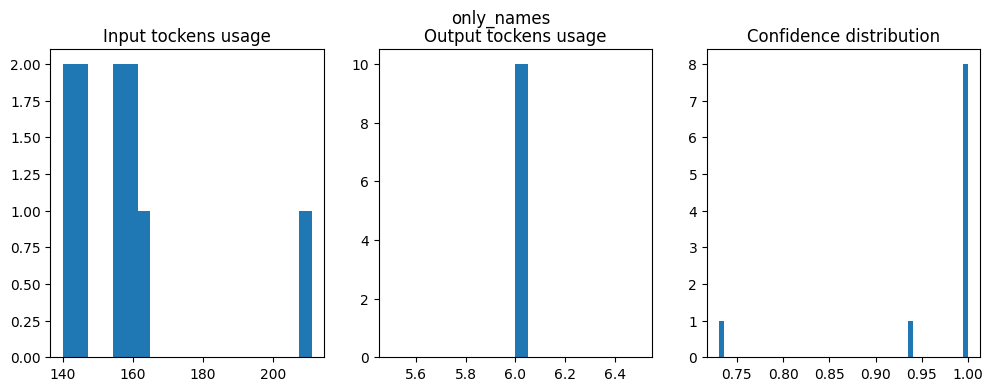

Accuracy: 0.60
Precision: 0.75
Recall: 0.75
F1 Score: 0.75


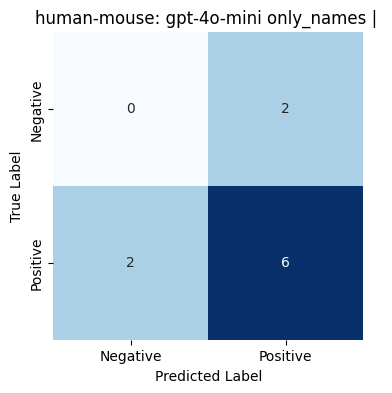

In [ ]:
MAX_WORKERS = 6
MODEL = "gpt-4o-mini"

EXP_NAMES_TO_PROMPT_FUNCTIONS = {
    "only_names": prompt_only_names,
    "with_hierarchy": prompt_with_hierarchy,
    "only_with_parents": prompt_only_with_parents,
    "only_with_children": prompt_only_with_children,
    "synonyms_subsumption": prompt_synonyms_subsumption,
    "one_name_one_synonym": prompt_one_name_one_synonym,
}


candidate_pairs_lines = read_candidate_pairs_file(DATASET_NAME, SET_NAME)[:10]

for current_exp_name, prompt_function in EXP_NAMES_TO_PROMPT_FUNCTIONS.items():

    results, tokens_usage, confidences = parallel_samples_process(
        candidate_pairs_lines, llm_oracle, onto_src, onto_tgt, MODEL, MAX_WORKERS, prompt_function
    )
    plot_usage_histograms(tokens_usage, confidences, do_plot=True, do_print=True, suptitle=current_exp_name)

    prediction_path = format_oracle_predictions_filepath(SET_NAME, MODEL, current_exp_name)
    save_oracle_results(results, prediction_path)

    predictions = get_predictions_with_gt(DATASET_NAME, SET_NAME, MODEL, current_exp_name)

    confusion_matrix_save_path = format_confusion_matrix_filepath(SET_NAME, MODEL, current_exp_name, suffix='dev')
    analyze_results(
        predictions,
        print_results=True,
        plot_confusion_matrix=True,
        subtitle=f"{SET_NAME}: {MODEL} {current_exp_name} | ",
        cm_save_path=confusion_matrix_save_path,
    )
    print("\n\n\n")
    break


## Results analysis

Accuracy: 0.60
Precision: 0.75
Recall: 0.75
F1 Score: 0.75


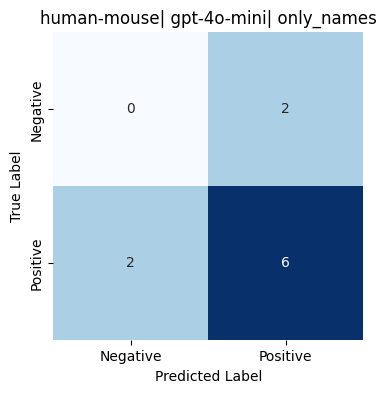

(0.6,
 0.75,
 0.75,
 0.75,
 array([[0, 2],
        [2, 6]]))

In [ ]:
exp_name = "only_names"
predictions = get_predictions_with_gt(DATASET_NAME, SET_NAME, MODEL, exp_name)
analyze_results(
    predictions, print_results=True, plot_confusion_matrix=True, subtitle=f"{SET_NAME}| {MODEL}| {exp_name}"
);

## analyze false predictions

In [ ]:
def print_results_entry(res_df:pd.DataFrame, pair_type:str="FP", idx:int=0) -> None:
    source_uri = res_df[res_df["Type"] == pair_type].iloc[idx]["Source"]
    target_uri = res_df[res_df["Type"] == pair_type].iloc[idx]["Target"]

    try:
        source_entry = OntologyEntryAttr(source_uri, onto_src)
        target_entry = OntologyEntryAttr(target_uri, onto_tgt)
    except Exception:
        source_entry = OntologyEntryAttr(source_uri, onto_tgt)
        target_entry = OntologyEntryAttr(target_uri, onto_src)

    print(f"Processing pair {idx} of type {pair_type}")
    pprint("Source Entry:\n")
    pprint(source_entry.annotation)
    pprint("Target Entry:\n")
    pprint(target_entry.annotation)

    print(f"Parent of Source Concept: {source_entry.get_parents_preferred_names()}")
    print(f"Parent of Target Concept: {target_entry.get_parents_preferred_names()}")

In [ ]:
exp_name = "only_names"
res_df = get_predictions_with_gt(DATASET_NAME, SET_NAME, model='gpt-4o-mini', exp_name=exp_name)

In [80]:
res_df

,Source,Target,Prediction,Confidence,Label,Type
0,http://human.owl#NCI_C53050,http://mouse.owl#MA_0002234,True,0.999999,False,FP
1,http://human.owl#NCI_C12262,http://mouse.owl#MA_0001615,True,0.999990,True,TP
2,http://human.owl#NCI_C33743,http://mouse.owl#MA_0002390,False,0.999876,True,FN
3,http://human.owl#NCI_C32658,http://mouse.owl#MA_0002684,False,0.817569,True,FN
4,http://human.owl#NCI_C33748,http://mouse.owl#MA_0001221,True,0.999999,True,TP
5,http://human.owl#NCI_C33075,http://mouse.owl#MA_0001249,True,0.999992,True,TP
6,http://human.owl#NCI_C32497,http://mouse.owl#MA_0000451,True,0.999999,True,TP
7,http://human.owl#NCI_C33627,http://mouse.owl#MA_0001460,True,0.939912,False,FP
8,http://human.owl#NCI_C33791,http://mouse.owl#MA_0000777,True,0.999998,True,TP
9,http://human.owl#NCI_C12909,http://mouse.owl#MA_0002434,True,0.999999,True,TP


In [81]:
print_results_entry(res_df, pair_type='FP', idx=0)

Processing pair 0 of type FP
'Source Entry:\n'
{'children': {human.NCI_C53050, human.NCI_C52696, human.NCI_C52697},
 'class': human.NCI_C53050,
 'names': {'Internal Spermatic Vein',
           'Spermatic Vein',
           'Spermatic_Vein',
           'Testicular Vein'},
 'parents': {owl.Thing,
             human.NCI_C12219,
             human.NCI_C32221,
             human.NCI_C12814,
             human.NCI_C25762,
             human.NCI_C12679,
             human.NCI_C53050},
 'synonyms': {'Internal Spermatic Vein', 'Spermatic Vein', 'Testicular Vein'}}
'Target Entry:\n'
{'children': {mouse.MA_0002234},
 'class': mouse.MA_0002234,
 'names': {'testicular vein'},
 'parents': {owl.Thing,
             mouse.MA_0000067,
             mouse.MA_0002234,
             mouse.MA_0000060,
             mouse.MA_0000066},
 'synonyms': {}}
Parent of Source Concept: [{owl.Thing}, {'Anatomic_Structure_System_or_Substance'}, {'Blood_Vessel'}, {'Vein'}, {'Cardiovascular_System_Part'}, {'Body_Part'}]
Pare